# 🛡️ AgriShield — Multi-Task EfficientNet-B0 Training Notebook

**Trains a lightweight dual-head CNN for:**
- **Head 1**: Disease Classification (Leaf + Root diseases)
- **Head 2**: Severity Estimation (Early / Moderate / Severe)

**Datasets (Public Direct Mirrors — No Login or Kaggle Token Needed):**
- **PlantVillage**: Primary benchmark training & validation dataset
- **PlantDoc**: Real-world unconstrained field test dataset

---
**Runtime → Change runtime type → T4 GPU**

In [ ]:
# ─── Step 1: Install Dependencies ───
!pip install -q torch torchvision timm matplotlib seaborn scikit-learn pillow

In [ ]:
# ─── Step 2: Download PlantVillage and PlantDoc Datasets ───
import os

print('[1/2] Downloading Official PlantVillage Dataset via Public Direct Mirror...')
if not os.path.exists('/content/plantvillage_raw'):
    !git clone https://github.com/spmohanty/PlantVillage-Dataset.git /content/plantvillage_raw

os.makedirs('/content/dataset/plantvillage dataset/color', exist_ok=True)
!cp -rf /content/plantvillage_raw/raw/color/* "/content/dataset/plantvillage dataset/color/"

print('\n[2/2] Downloading Official PlantDoc Dataset via Public Direct Mirror...')
if not os.path.exists('./dataset_pd'):
    !git clone https://github.com/pratikkayal/PlantDoc-Dataset.git ./dataset_pd

# Set Global Paths
DATA_DIR = '/content/dataset/plantvillage dataset/color'
PD_DATA_DIR = './dataset_pd/TRAIN'

print(f'\n✅ DATA_DIR set to: {DATA_DIR}')
print(f'✅ PD_DATA_DIR set to: {PD_DATA_DIR}')

[1/2] Downloading Official PlantVillage Dataset via Public Direct Mirror...
Cloning into '/content/plantvillage_raw'...
remote: Enumerating objects: 163264, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 163264 (delta 16), reused 25 (delta 9), pack-reused 163229 (from 1)
Receiving objects: 100% (163264/163264), 2.00 GiB | 25.80 MiB/s, done.
Resolving deltas: 100% (115/115), done.
Updating files: 100% (182404/182404), done.

[2/2] Downloading Official PlantDoc Dataset via Public Direct Mirror...
Cloning into './dataset_pd'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 45.10 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.

✅ DATA_DIR set to: /content/dataset/pl

In [ ]:
# ─── Step 3: Explore Dataset ───
import os

classes = sorted(os.listdir(DATA_DIR))
print(f'Total disease classes found: {len(classes)}')
print('─' * 50)

total_images = 0
for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    if os.path.isdir(cls_path):
        count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        total_images += count
        print(f'  {cls}: {count} images')

print(f'\nTotal images: {total_images:,}')

Total disease classes found: 38
──────────────────────────────────────────────────
  Apple___Apple_scab: 630 images
  Apple___Black_rot: 621 images
  Apple___Cedar_apple_rust: 275 images
  Apple___healthy: 1645 images
  Blueberry___healthy: 1502 images
  Cherry_(including_sour)___Powdery_mildew: 1052 images
  Cherry_(including_sour)___healthy: 854 images
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
  Corn_(maize)___Common_rust_: 1192 images
  Corn_(maize)___Northern_Leaf_Blight: 985 images
  Corn_(maize)___healthy: 1162 images
  Grape___Black_rot: 1180 images
  Grape___Esca_(Black_Measles): 1383 images
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
  Grape___healthy: 423 images
  Orange___Haunglongbing_(Citrus_greening): 5507 images
  Peach___Bacterial_spot: 2297 images
  Peach___healthy: 360 images
  Pepper,_bell___Bacterial_spot: 997 images
  Pepper,_bell___healthy: 1478 images
  Potato___Early_blight: 1000 images
  Potato___Late_blight: 1000 images
  P

In [ ]:
# ─── Step 4: Define Multi-Task Model Architecture ───
import torch
import torch.nn as nn
import torchvision.models as models

class CropDiseaseModel(nn.Module):
    """
    Multi-Task EfficientNet-B0
    ─────────────────────────
    Backbone : EfficientNet-B0 (5.3M params, ~20MB)
    Head 1   : Disease Classification  (1280 → 256 → num_classes)
    Head 2   : Severity Estimation     (1280 → 128 → 3)
    """
    def __init__(self, num_classes, num_severities=3):
        super().__init__()
        self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        in_features = self.backbone.classifier[1].in_features  # 1280
        self.backbone.classifier = nn.Identity()

        self.disease_head = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

        self.severity_head = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_severities),
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.disease_head(features), self.severity_head(features)

print('✅ CropDiseaseModel architecture defined')

✅ CropDiseaseModel architecture defined


In [ ]:
# ─── Step 5: Prepare DataLoaders with Augmentation ───
import torchvision.transforms as T
from torchvision import datasets
from torch.utils.data import DataLoader, random_split

# Training transforms with strong augmentation
train_transform = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    T.RandomGrayscale(p=0.05),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load full dataset
full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transform)
num_classes = len(full_dataset.classes)

# 85/15 train-val split
val_size = int(0.15 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f'✅ Dataset: {len(full_dataset):,} images | {num_classes} classes')
print(f'   Train: {train_size:,} | Val: {val_size:,}')
print(f'   Classes: {full_dataset.classes}')

✅ Dataset: 54,305 images | 38 classes
   Train: 46,160 | Val: 8,145
   Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_

In [ ]:
# ─── Step 6: Initialize Model, Optimizer, Scheduler ───
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Training device: {device}')

model = CropDiseaseModel(num_classes=num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'Model size: ~{total_params * 4 / 1024 / 1024:.1f} MB')

# Optimizer & Scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

disease_criterion = nn.CrossEntropyLoss()
severity_criterion = nn.CrossEntropyLoss()

SEVERITY_LAMBDA = 0.5  # Weight for severity loss
NUM_EPOCHS = 15

print(f'\n✅ Ready to train for {NUM_EPOCHS} epochs')

Training device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


Total parameters: 4,510,373
Trainable parameters: 4,510,373
Model size: ~17.2 MB

✅ Ready to train for 15 epochs


In [ ]:
# ─── Step 7: Training Loop ───
import time

def get_severity_target(labels, class_list):
    severities = []
    for label in labels:
        c_name = class_list[label.item()].lower()
        if 'healthy' in c_name:
            severities.append(0)  # Early / Healthy
        elif 'spot' in c_name or 'scorch' in c_name or 'mildew' in c_name:
            severities.append(1)  # Moderate
        else:
            severities.append(2)  # Severe
    return torch.tensor(severities, dtype=torch.long)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()

    # ── Train ──
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        severity_labels = get_severity_target(labels, full_dataset.classes).to(device)

        optimizer.zero_grad()
        disease_logits, severity_logits = model(images)

        loss_d = disease_criterion(disease_logits, labels)
        loss_s = severity_criterion(severity_logits, severity_labels)
        loss = loss_d + SEVERITY_LAMBDA * loss_s

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(disease_logits, 1)
        train_correct += (preds == labels).sum().item()
        train_total += images.size(0)

    # ── Validate ──
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            severity_labels = get_severity_target(labels, full_dataset.classes).to(device)

            disease_logits, severity_logits = model(images)
            loss_d = disease_criterion(disease_logits, labels)
            loss_s = severity_criterion(severity_logits, severity_labels)
            loss = loss_d + SEVERITY_LAMBDA * loss_s

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(disease_logits, 1)
            val_correct += (preds == labels).sum().item()
            val_total += images.size(0)

    scheduler.step()

    # ── Metrics ──
    t_loss = train_loss / train_total
    t_acc = train_correct / train_total * 100
    v_loss = val_loss / val_total
    v_acc = val_correct / val_total * 100
    elapsed = time.time() - start

    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)

    saved = ''
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': v_acc,
            'num_classes': num_classes,
            'class_names': full_dataset.classes,
        }, 'crop_disease_model.pth')
        saved = ' ✓ SAVED'

    print(f'Epoch {epoch:2d}/{NUM_EPOCHS} │ '
          f'Train {t_loss:.3f} / {t_acc:.1f}% │ '
          f'Val {v_loss:.3f} / {v_acc:.1f}% │ '
          f'{elapsed:.0f}s{saved}')

print(f'\n🏆 Best validation accuracy: {best_val_acc:.1f}%')

Epoch  1/15 │ Train 0.471 / 89.1% │ Val 0.245 / 94.0% │ 468s ✓ SAVED
Epoch  2/15 │ Train 0.206 / 95.0% │ Val 0.099 / 97.4% │ 464s ✓ SAVED
Epoch  3/15 │ Train 0.172 / 95.8% │ Val 0.100 / 97.5% │ 468s ✓ SAVED
Epoch  4/15 │ Train 0.145 / 96.5% │ Val 0.085 / 97.9% │ 474s ✓ SAVED
Epoch  5/15 │ Train 0.116 / 97.2% │ Val 0.093 / 97.5% │ 462s
Epoch  6/15 │ Train 0.100 / 97.5% │ Val 0.064 / 98.5% │ 464s ✓ SAVED
Epoch  7/15 │ Train 0.078 / 98.1% │ Val 0.038 / 99.0% │ 465s ✓ SAVED
Epoch  8/15 │ Train 0.061 / 98.6% │ Val 0.057 / 98.7% │ 461s
Epoch  9/15 │ Train 0.049 / 98.8% │ Val 0.055 / 98.6% │ 465s
Epoch 10/15 │ Train 0.039 / 99.1% │ Val 0.030 / 99.2% │ 466s ✓ SAVED
Epoch 11/15 │ Train 0.028 / 99.3% │ Val 0.021 / 99.5% │ 458s ✓ SAVED
Epoch 12/15 │ Train 0.022 / 99.4% │ Val 0.019 / 99.6% │ 460s ✓ SAVED
Epoch 13/15 │ Train 0.017 / 99.6% │ Val 0.019 / 99.5% │ 459s
Epoch 14/15 │ Train 0.014 / 99.7% │ Val 0.018 / 99.6% │ 462s ✓ SAVED
Epoch 15/15 │ Train 0.014 / 99.7% │ Val 0.015 / 99.7% │ 457s ✓ SAV

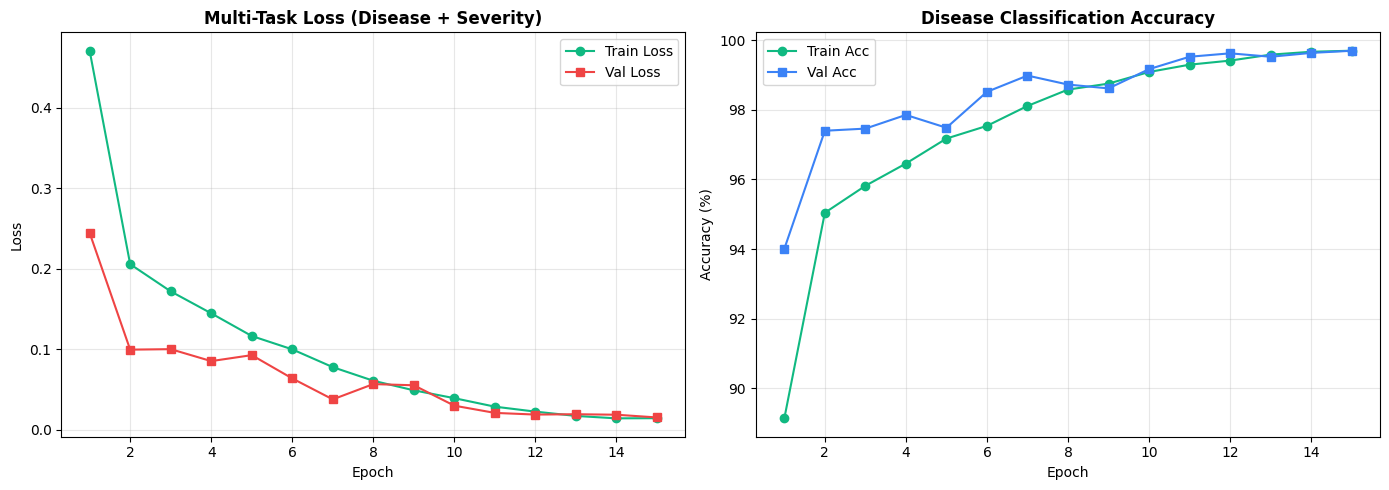

📊 Saved training_curves.png


In [ ]:
# ─── Step 8: Plot Training Curves ───
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history['train_loss']) + 1)

ax1.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='#10b981')
ax1.plot(epochs_range, history['val_loss'], 's-', label='Val Loss', color='#ef4444')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Multi-Task Loss (Disease + Severity)', fontweight='bold')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_range, history['train_acc'], 'o-', label='Train Acc', color='#10b981')
ax2.plot(epochs_range, history['val_acc'], 's-', label='Val Acc', color='#3b82f6')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Disease Classification Accuracy', fontweight='bold')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Saved training_curves.png')

In [1]:
# ─── Step 9: Export Final Model ───
import os
from google.colab import files

model_path = 'crop_disease_model.pth'
model_size = os.path.getsize(model_path) / (1024 * 1024)

print('=' * 60)
print('  🏆 MODEL TRAINING COMPLETE')
print('=' * 60)
print(f'  File           : {model_path}')
print(f'  Size           : {model_size:.1f} MB')
print(f'  Best Val Acc   : {best_val_acc:.1f}%')
print(f'  Disease Classes: {num_classes}')
print(f'  Severity Heads : 3 (Early / Moderate / Severe)')
print('=' * 60)

try:
    files.download('crop_disease_model.pth')
    files.download('training_curves.png')
except:
    print('Not in Colab — manually copy crop_disease_model.pth to your project.')

FileNotFoundError: [Errno 2] No such file or directory: 'crop_disease_model.pth'